In [19]:
import tensorflow as tf
import matplotlib.pyplot as plt
import os
import re
import shutil
import string
from tensorflow.keras import layers,losses

## Sentiment analysis

In [3]:
url = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"
dataset = tf.keras.utils.get_file('aclImdb_v1', url,untar = True,cache_dir='.',cache_subdir='')
dataset_dir = os.path.join(os.path.dirname(dataset), 'aclImdb')

84140032/84125825 [==============================] - 3s 0us/step


In [4]:
os.listdir(dataset_dir)

['test', 'train', 'imdb.vocab', 'imdbEr.txt', 'README']

In [5]:
train_dir = os.path.join(dataset_dir, 'train')
os.listdir(train_dir)


['neg',
 'urls_pos.txt',
 'pos',
 'urls_neg.txt',
 'unsup',
 'labeledBow.feat',
 'unsupBow.feat',
 'urls_unsup.txt']

In [6]:
pos_dir = os.path.join(train_dir, 'pos')
os.listdir(pos_dir)


['9353_8.txt',
 '2207_9.txt',
 '7406_9.txt',
 '5564_10.txt',
 '9702_10.txt',
 '9379_7.txt',
 '11649_10.txt',
 '4457_8.txt',
 '8343_7.txt',
 '8909_9.txt',
 '7639_8.txt',
 '7365_7.txt',
 '7221_8.txt',
 '1986_10.txt',
 '6479_10.txt',
 '5752_8.txt',
 '8430_9.txt',
 '9937_10.txt',
 '11618_8.txt',
 '11372_7.txt',
 '10401_10.txt',
 '1457_10.txt',
 '2278_10.txt',
 '9369_10.txt',
 '12436_7.txt',
 '7575_10.txt',
 '7865_8.txt',
 '1617_8.txt',
 '10414_10.txt',
 '5641_7.txt',
 '10936_8.txt',
 '1743_9.txt',
 '2676_10.txt',
 '9470_8.txt',
 '5910_8.txt',
 '9675_8.txt',
 '8364_10.txt',
 '2643_10.txt',
 '3292_10.txt',
 '6932_7.txt',
 '7171_10.txt',
 '5327_10.txt',
 '825_10.txt',
 '6437_9.txt',
 '623_10.txt',
 '11707_10.txt',
 '8143_10.txt',
 '11176_9.txt',
 '10851_9.txt',
 '8533_8.txt',
 '3117_8.txt',
 '6583_7.txt',
 '2345_9.txt',
 '11554_8.txt',
 '7175_10.txt',
 '4138_10.txt',
 '11154_10.txt',
 '7417_10.txt',
 '4227_10.txt',
 '8225_8.txt',
 '10486_7.txt',
 '4067_8.txt',
 '7923_8.txt',
 '6668_8.txt',
 '

In [9]:
sample_file = os.path.join(train_dir, 'pos/1181_9.txt')
with open(sample_file) as f:
  print(f.read())

Rachel Griffiths writes and directs this award winning short film. A heartwarming story about coping with grief and cherishing the memory of those we've loved and lost. Although, only 15 minutes long, Griffiths manages to capture so much emotion and truth onto film in the short space of time. Bud Tingwell gives a touching performance as Will, a widower struggling to cope with his wife's death. Will is confronted by the harsh reality of loneliness and helplessness as he proceeds to take care of Ruth's pet cow, Tulip. The film displays the grief and responsibility one feels for those they have loved and lost. Good cinematography, great direction, and superbly acted. It will bring tears to all those who have lost a loved one, and survived.


main_directory/

...class_a/

......a_text_1.txt

......a_text_2.txt

...class_b/

......b_text_1.txt

......b_text_2.txt

In [11]:
remove_dir = os.path.join(train_dir, 'unsup')
shutil.rmtree(remove_dir)

In [12]:
batch_size = 32
seed = 42

raw_train_ds = tf.keras.utils.text_dataset_from_directory(
    'aclImdb/train', 
    batch_size=batch_size, 
    validation_split=0.2, 
    subset='training', 
    seed=seed)

Found 25000 files belonging to 2 classes.
Using 20000 files for training.


In [14]:
for text_batch, label_batch in raw_train_ds.take(1):
  for i in range(3):
    print('Review',text_batch.numpy()[i])
    print('Label',label_batch.numpy()[i])
    

Review b"Having seen most of Ringo Lam's films, I can say that this is his best film to date, and the most unusual. It's a ancient china period piece cranked full of kick-ass martial arts, where the location of an underground lair full of traps and dungeons plays as big a part as any of the characters. The action is fantastic, the story is tense and entertaining, and the set design is truely memorable. Sadly, Burning Paradise has not been made available on DVD and vhs is next-to-impossible to get your mitts on, even if you near the second biggest china-town in North America (like I do). If you can find it, don't pass it up."
Label 1
Review b'Caution: May contain spoilers...<br /><br />I\'ve seen this movie 3 times & I\'ve liked it every time. Upon seeing it again, I\'m always reminded of how good it is. An HBO TV movie- very well done like most of their movies are- this would\'ve gotten Oscars for it\'s performances had it been released for general distribution instead of made for TV.<

In [15]:
print('Label 0 corresponds to', raw_train_ds.class_names[0])
print('Label 0 corresponds to', raw_train_ds.class_names[1])

Label 0 corresponds to neg
Label 0 corresponds to pos


In [17]:
raw_val_ds = tf.keras.utils.text_dataset_from_directory(
    'aclImdb/train',
    batch_size = batch_size,
    validation_split = 0.2,
    subset='validation',
    seed = seed 
)

Found 25000 files belonging to 2 classes.
Using 5000 files for validation.


In [18]:
raw_test_ds = tf.keras.utils.text_dataset_from_directory(
    'aclImdb/test',
    batch_size = batch_size
)

Found 25000 files belonging to 2 classes.


In [20]:
def custom_standardization(input_data):
  lowercase = tf.strings.lower(input_data)
  stripped_html = tf.strings.regex_replace(lowercase, '<br/ >', ' ')
  return tf.strings.regex_replace(stripped_html,'[%s]'% re.escape(string.punctuation),'')

In [21]:
max_features = 10000
sequence_length = 250

vectorize_layer = layers.TextVectorization(
    standardize = custom_standardization,
    max_tokens = max_features,
    output_mode = 'int',
    output_sequence_length = sequence_length
)

In [22]:
train_text = raw_train_ds.map(lambda x,y:x)
vectorize_layer.adapt(train_text)


In [23]:
def vectorize_text(text,label):
  text = tf.expand_dims(text, -1)
  return vectorize_layer(text), label

In [24]:
text_batch, label_batch = next(iter(raw_train_ds))
first_review, first_label = text_batch[0], label_batch[0]
print('Review', first_review)
print('Label',raw_train_ds.class_names[first_label])
print('Vectorized review',vectorize_text(first_review,first_label))

Review tf.Tensor(b'Belmondo is a tough cop. He goes after a big-time drug dealer (played by Henry Silva, normally a great villain - see "Sharky\'s Machine"; but here he is clearly dubbed, and because of that he lacks his usual charisma). He goes to the scuzziest places of Paris and Marseilles, asks for some names, beats up some people, gets the names, goes to more scuzzy places, asks for more names, beats up more people, etc. The whole movie is punch after punch after punch. It seems that the people who made it had no other ambition than to create the French equivalent of "Dirty Harry". Belmondo, who was 50 here, does perform some good stunts at the beginning; apart from those, "Le Marginal" is a violent, episodic, trite, shallow and forgettable cop movie. (*1/2)', shape=(), dtype=string)
Label neg
Vectorized review (<tf.Tensor: shape=(1, 250), dtype=int64, numpy=
array([[   1,    7,    4, 1223, 1022,   28,  262,  101,    4,    1, 1510,
        7037,  247,   33, 1482,    1, 1654,    4,

In [25]:
print("1287 ---> ",vectorize_layer.get_vocabulary()[1287])
print(" 313 ---> ",vectorize_layer.get_vocabulary()[313])
print('Vocabulary size: {}'.format(len(vectorize_layer.get_vocabulary())))

1287 --->  naked
 313 --->  night
Vocabulary size: 10000


In [26]:
train_ds = raw_train_ds.map(vectorize_text)
val_ds = raw_val_ds.map(vectorize_text)
test_ds = raw_test_ds.map(vectorize_text)

In [27]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [28]:
embedding_dim = 16

In [29]:
model = tf.keras.Sequential([
  layers.Embedding(max_features + 1, embedding_dim),
  layers.Dropout(0.2),
  layers.GlobalAveragePooling1D(),
  layers.Dropout(0.2),
  layers.Dense(1)])

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, None, 16)          160016    
                                                                 
 dropout (Dropout)           (None, None, 16)          0         
                                                                 
 global_average_pooling1d (G  (None, 16)               0         
 lobalAveragePooling1D)                                          
                                                                 
 dropout_1 (Dropout)         (None, 16)                0         
                                                                 
 dense (Dense)               (None, 1)                 17        
                                                                 
Total params: 160,033
Trainable params: 160,033
Non-trainable params: 0
__________________________________________________

In [30]:
model.compile(loss=losses.BinaryCrossentropy(from_logits=True),
              optimizer='adam',
              metrics=tf.metrics.BinaryAccuracy(threshold=0.0))

In [31]:
epochs = 10
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs)

Epoch 1/10
625/625 [==============================] - 14s 16ms/step - loss: 0.6645 - binary_accuracy: 0.6873 - val_loss: 0.6157 - val_binary_accuracy: 0.7722
Epoch 2/10
625/625 [==============================] - 4s 7ms/step - loss: 0.5506 - binary_accuracy: 0.7992 - val_loss: 0.5004 - val_binary_accuracy: 0.8194
Epoch 3/10
625/625 [==============================] - 4s 7ms/step - loss: 0.4478 - binary_accuracy: 0.8440 - val_loss: 0.4235 - val_binary_accuracy: 0.8476
Epoch 4/10
625/625 [==============================] - 4s 7ms/step - loss: 0.3813 - binary_accuracy: 0.8648 - val_loss: 0.3772 - val_binary_accuracy: 0.8596
Epoch 5/10
625/625 [==============================] - 4s 7ms/step - loss: 0.3381 - binary_accuracy: 0.8772 - val_loss: 0.3484 - val_binary_accuracy: 0.8658
Epoch 6/10
625/625 [==============================] - 4s 7ms/step - loss: 0.3091 - binary_accuracy: 0.8880 - val_loss: 0.3293 - val_binary_accuracy: 0.8704
Epoch 7/10
625/625 [==============================] - 4s 7ms/s

In [32]:
loss, accuracy = model.evaluate(test_ds)

print("Loss: ", loss)
print("Accuracy: ", accuracy)

782/782 [==============================] - 9s 11ms/step - loss: 0.3128 - binary_accuracy: 0.8723
Loss:  0.3128497004508972
Accuracy:  0.8722800016403198


In [33]:
history_dict = history.history
history_dict.keys()

dict_keys(['loss', 'binary_accuracy', 'val_loss', 'val_binary_accuracy'])

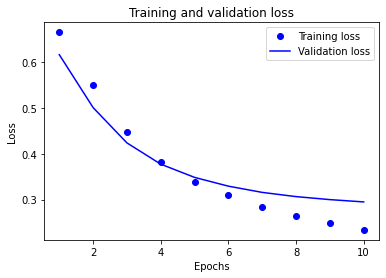

In [34]:
acc = history_dict['binary_accuracy']
val_acc = history_dict['val_binary_accuracy']
loss = history_dict['loss']
val_loss = history_dict['val_loss']

epochs = range(1, len(acc) + 1)

# "bo" is for "blue dot"

plt.plot(epochs, loss, 'bo', label='Training loss')

# b is for "solid blue line"

plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

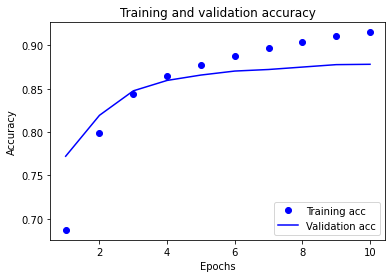

In [35]:
plt.plot(epochs, acc, 'bo', label='Training acc')
plt.plot(epochs, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')

plt.show()

## Export the model

In [36]:
export_model = tf.keras.Sequential([
  vectorize_layer,
  model,
  layers.Activation('sigmoid')
])

export_model.compile(
    loss=losses.BinaryCrossentropy(from_logits=False), optimizer="adam", metrics=['accuracy']
)

# Test it with `raw_test_ds`, which yields raw strings
loss, accuracy = export_model.evaluate(raw_test_ds)
print(accuracy)

782/782 [==============================] - 10s 12ms/step - loss: 0.3128 - accuracy: 0.8723
0.8722800016403198


In [37]:
examples = [
  "The movie was great!",
  "The movie was okay.",
  "The movie was terrible..."
]

export_model.predict(examples)

array([[0.6445441 ],
       [0.47585937],
       [0.38728476]], dtype=float32)